# Phase 3: Base Model Evaluation (`SimpleStories` Test, Story Cloze & Pre-SFT Baseline)

Evaluates the Phase 2/3 **RoPE Pre-Trained Base Model** (`23a72f3a...`) across held-out `SimpleStories` test metrics, RoPE context scaling (`1–1,024`), 4-choice Story Cloze (`story_mc_acc`), long-context narrative recall, pre-SFT zero-shot arithmetic baseline, and inference throughput.

In [1]:
from pathlib import Path
import sys

root = next((p for p in (Path.cwd(), *Path.cwd().parents) if (p / "src" / "main.py").is_file()), Path.cwd().parent)
if str(root) not in sys.path:
    sys.path.insert(0, str(root))

from src.infra.eval_setup import setup_notebook_environment, configure_eval_device

project_root = setup_notebook_environment(root)
device, dtype = configure_eval_device("auto")  # 'auto', 'cuda', or 'cpu'

Project root located at: C:\Users\sampa\Dev\MiniReasoner
ACTIVE EXECUTION DEVICE: CPU
CPU Threads:        4
Inference Dtype:    torch.float32
Mode:               Portable CPU Inference


c:\Users\sampa\Dev\MiniReasoner\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Load Pre-Trained Base Checkpoint

Discovered 8 run(s) in Azure container 'minireasoner':

Run ID                              Stage     Format      MLflow State  Snapshots  Last Updated (UTC)
--------------------------------------------------------------------------------------------------------
23a72f3aa8d6487ca401b92b22ae229c    pretrain  -           active        53         2026-11-24 19:09:03
655ddf770790468d988bbb0375fd5aa4    pretrain  -           active        48         2026-11-24 09:22:26
e57bf52bb95842dba6628092261584c4    sft       scratchpad  active        20         2026-11-26 05:56:23
ef3cc27cede44edf90ff5f205a2f71d6    sft       direct      active        16         2026-11-25 17:43:41
e8996fa3b67f48c8951cfd20f68ab40b    sft       direct      active        6          2026-11-25 17:17:13
c26cf6e5ffc749e69b298d27f33ca243    pretrain  -           deleted       4          2026-11-24 15:11:38
6ef108a339da46679718b67143c39e2e    sft       scratchpad  deleted       4          2026-11-26 05:15:53
f9a6d03c46af4a37

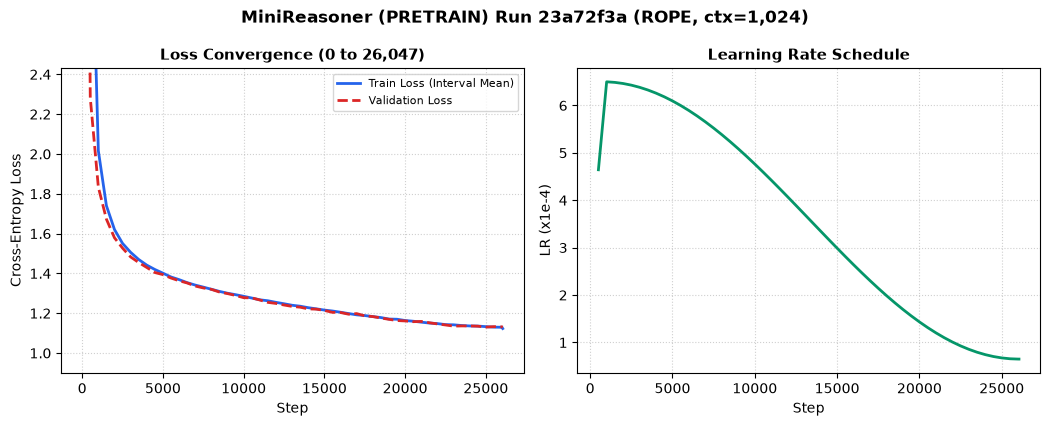

Initial Val Loss:        7.0470 (Step 0)
Latest Logged Val Loss:  1.1303 (Step 26,047)
Best Val Loss:           1.1302 (Step 25,000)
Mean Train Throughput:   137,848 tok/s


In [2]:
from src.infra.eval_setup import select_run_and_checkpoint, load_checkpoint_bundle, plot_run_history

RUN_ID = None                # Auto-selects newest active pre-training run (23a72f3a...)
CHECKPOINT_ALIAS = "latest"  # 'latest' (step 26,047) or 'best' (step 25,000)
LOCAL_CHECKPOINT = None

run_id, ckpt_path, snapshot = select_run_and_checkpoint(
    run_id=RUN_ID,
    checkpoint_alias=CHECKPOINT_ALIAS,
    local_checkpoint=LOCAL_CHECKPOINT,
    preferred_stages=("pretrain", "base", ""),
)
bundle = load_checkpoint_bundle(ckpt_path, device, dtype, snapshot=snapshot)
model, tokenizer, model_config = bundle["model"], bundle["tokenizer"], bundle["model_config"]
plot_run_history(bundle["metrics_history"], run_id=run_id, model_config=model_config, stage=bundle["stage"], snapshot=snapshot)

## 2. Held-Out `SimpleStories` Test PPL, BPB, RoPE Scaling & Story Cloze

In [3]:
from src.core.benchmark import evaluate_simplestories_test

story_metrics = evaluate_simplestories_test(model, tokenizer, model_config, device)

HELD-OUT TEST EVALUATION | SimpleStories/SimpleStories (test split)
Stories Scored:          64
Predicted Tokens:        27,124 (81,872 UTF-8 bytes | 3.02 bytes/tok)
Test Cross-Entropy Loss: 1.1532
Test Perplexity (PPL):   3.17
Test Bits-Per-Byte(BPB): 0.5512
----------------------------------------------------------------------
RoPE Context-Length Position Scaling:
  Tokens 1-256      | count=15,332  | Loss=1.1844 | PPL=3.27
  Tokens 257-512    | count=8,279   | Loss=1.1149 | PPL=3.05
  Tokens 513-1024   | count=3,513   | Loss=1.1078 | PPL=3.03

4-Choice Story Cloze Accuracy: 35/40 (87.5%) [Random baseline: 25.0%]

STORY COMPLETION SANITY CHECK (Greedy on CPU)
[1] (59.1 tok/s) Once upon a time, there was a little girl named Mia who loved to explore. One day, she found a shiny rock in her backyard. It sparkled like stars in the night sky. Mia picked it up and felt a warm glow in her hand. She thought it was magic! 

Mia decided to show her friends. She ran to the big tree in the park. 

## 3. Long-Context RoPE & Sampling Completions

In [4]:
import torch
from src.core.benchmark import generate_timed

torch.manual_seed(42)
long_prompt = (
    "Once upon a time, in a quiet village beside a silver river, there lived a young clockmaker named Clara. "
    "Every morning she swept the wooden floor of her shop, polished the brass gears on the workbench, and checked the tall grandfather clock by the window. "
    "The villagers loved visiting Clara because she could repair anything from tiny pocket watches to musical jewelry boxes. "
    "One autumn afternoon, an old traveler in a heavy wool coat stepped inside carrying a locked lantern made of dark iron and blue glass. "
    "He placed the lantern gently on the counter and told Clara that it had belonged to the lighthouse keeper many years ago before the storm broke its chime. "
    "Clara examined the delicate copper springs inside, took out her smallest magnifying lens, and noticed an engraved map hidden beneath the brass dial. "
    "Together with her clever fox Pip, who always slept near the warm stove, Clara carefully turned the tiny silver screw at the base of the lantern. "
    "With a soft click, the blue glass door swung open and revealed a glowing compass pointing north toward the misty hills. "
    "Clara looked at Pip, smiled, and reached for her wool scarf because she knew their adventure was about to begin. "
    "As she held the glowing compass and walked out onto the cobblestone street with"
)
n_tok = len(tokenizer.encode(long_prompt, add_special_tokens=False).ids)
print(f"Long-context prompt ({n_tok} tokens):")
long_res = generate_timed(model, tokenizer, long_prompt, max_new_tokens=100, temperature=0.0, device=device)
print(f"Greedy ({long_res['tokens_per_second']:.1f} tok/s):\n{long_res['completion'].strip()}")

sample_res = generate_timed(model, tokenizer, "Once upon a time, there was a little", max_new_tokens=90, temperature=0.7, top_p=0.9, device=device)
print(f"\nNucleus T=0.7 ({sample_res['tokens_per_second']:.1f} tok/s):\n{sample_res['full_text'].strip()}")

Long-context prompt (475 tokens):
Greedy (22.3 tok/s):
a warm feeling in her heart, she knew that the true treasure was the journey they shared together.

Nucleus T=0.7 (56.0 tok/s):
Once upon a time, there was a little boy named Leo who loved to play soccer. He dreamed of being the best player in the world. One day, he found an old soccer ball in his attic. It was dusty but had a strange glow. He kicked it, and it rolled to a clearing. To his surprise, the ball stopped, and a wis


## 4. Pre-SFT Arithmetic Baseline & Throughput

In [5]:
from src.core.benchmark import run_pre_sft_arithmetic_baseline, benchmark_throughput

baseline_results = run_pre_sft_arithmetic_baseline(model, tokenizer, device)
throughput_rows = benchmark_throughput(model, tokenizer, device)

ARITHMETIC BASELINE EVALUATION (Pre-Trained Base Model)
Prompt                   Target    Raw Model Output              Exact Match   Valid Format
-------------------------------------------------------------------------------------
What is 3 + 5? Answer:   8         1: What is 2? Blink!          False         False
What is 7 + 8? Answer:   15        "It's time!" The boy grinned. False         False
What is 12 + 15? Answer: 27        "An echo!" The group laughed, False         False
What is 47 + 8? Answer:  55        "An echo!" The crowd roared wiFalse         False
What is 38 + 24? Answer: 62        "An echo!" The crowd roared wiFalse         False
What is 9 - 4? Answer:   5         'What has keys but can't open False         False
What is 25 - 10? Answer: 15        1: What is 2: Why?" The boy   False         False
What is 52 - 17? Answer: 35        1: What is 2? Blast off!"     False         False
What is 43 - 18? Answer: 25        1: What has keys but can't opeFalse         False
W